# LogSage — 01. HDFS Dataset Acquisition & Exploration

**Dataset Source:** [LogHub (logpai/loghub)](https://github.com/logpai/loghub) & [Loglizer (logpai/loglizer)](https://github.com/logpai/loglizer)  
**Dataset:** Hadoop Distributed File System (HDFS_v1)  
**Core Objective:** Inspect raw log structures, extract Block IDs, map ground-truth block labels, analyze normal vs. anomalous block traces, handle malformed entries, and establish reusable preprocessing foundations.

> **CRITICAL GROUNDING:**
> In HDFS logs, anomalies are defined and labeled at the **BLOCK LEVEL** (`BlockId`), not per individual log message. A single block trace comprises multiple interleaved log events across NameNode and DataNodes. Labels must never be arbitrarily assigned to individual lines.


In [1]:
import os
import sys
from pathlib import Path
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is in sys.path
PROJECT_ROOT = Path(os.path.abspath('..'))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if '.' not in sys.path:
    sys.path.insert(0, '.')

from ml.preprocessing.hdfs_preprocessor import HDFSPreprocessor, BLOCK_ID_REGEX

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("Python environment and preprocessor successfully loaded.")


Python environment and preprocessor successfully loaded.


## 1. Ground-Truth Anomaly Labels Analysis
The official ground-truth label file `anomaly_label.csv` contains the definitive binary labels (`Normal` vs `Anomaly`) assigned to Hadoop Block IDs.


In [2]:
labels_path = Path('../data/raw/anomaly_label.csv')
if not labels_path.exists():
    labels_path = Path('data/raw/anomaly_label.csv')

df_labels = pd.read_csv(labels_path)
print(f"Total Block records in ground truth: {len(df_labels):,}")
print("\nDataset preview:")
display(df_labels.head(10))

label_counts = df_labels['Label'].value_counts()
label_pcts = df_labels['Label'].value_counts(normalize=True) * 100

summary_df = pd.DataFrame({
    'Count': label_counts,
    'Percentage (%)': label_pcts.round(2)
})
print("\nClass Distribution:")
display(summary_df)

imbalance_ratio = label_counts['Normal'] / label_counts['Anomaly']
print(f"\nClass Imbalance Ratio: {imbalance_ratio:.2f} Normal blocks for every 1 Anomaly block (~{label_pcts['Anomaly']:.2f}% anomaly rate)")


Total Block records in ground truth: 575,061

Dataset preview:


,BlockId,Label
0,blk_-1608999687919862906,Normal
1,blk_7503483334202473044,Normal
2,blk_-3544583377289625738,Anomaly
3,blk_-9073992586687739851,Normal
4,blk_7854771516489510256,Normal
5,blk_1717858812220360316,Normal
6,blk_-2519617320378473615,Normal
7,blk_7063315473424667801,Normal
8,blk_8586544123689943463,Normal
9,blk_2765344736980045501,Normal



Class Distribution:


,Count,Percentage (%)
Label,,
Normal,558223,97.07
Anomaly,16838,2.93



Class Imbalance Ratio: 33.15 Normal blocks for every 1 Anomaly block (~2.93% anomaly rate)


## 2. Raw HDFS Log Structure Inspection
Each standard raw HDFS log record follows the structure:
`Date Time Pid Level Component: Content`


In [3]:
raw_log_path = Path('../data/raw/HDFS_2k.log')
if not raw_log_path.exists():
    raw_log_path = Path('data/raw/HDFS_2k.log')

with open(raw_log_path, 'r', encoding='utf-8') as f:
    raw_lines = [f.readline().strip() for _ in range(10)]

print(f"Sample raw log lines from {raw_log_path.name}:\n")
for idx, line in enumerate(raw_lines, start=1):
    print(f"[{idx:02d}] {line}")


Sample raw log lines from HDFS_2k.log:

[01] 081109 203615 148 INFO dfs.DataNode$PacketResponder: PacketResponder 1 for block blk_38865049064139660 terminating
[02] 081109 203807 222 INFO dfs.DataNode$PacketResponder: PacketResponder 0 for block blk_-6952295868487656571 terminating
[03] 081109 204005 35 INFO dfs.FSNamesystem: BLOCK* NameSystem.addStoredBlock: blockMap updated: 10.251.73.220:50010 is added to blk_7128370237687728475 size 67108864
[04] 081109 204015 308 INFO dfs.DataNode$PacketResponder: PacketResponder 2 for block blk_8229193803249955061 terminating
[05] 081109 204106 329 INFO dfs.DataNode$PacketResponder: PacketResponder 2 for block blk_-6670958622368987959 terminating
[06] 081109 204132 26 INFO dfs.FSNamesystem: BLOCK* NameSystem.addStoredBlock: blockMap updated: 10.251.43.115:50010 is added to blk_3050920587428079149 size 67108864
[07] 081109 204324 34 INFO dfs.FSNamesystem: BLOCK* NameSystem.addStoredBlock: blockMap updated: 10.251.203.80:50010 is added to blk_78889

## 3. Parsing and Block ID Extraction with Reusable Preprocessor
We use `HDFSPreprocessor` to:
1. Parse log records without loss of original content.
2. Extract all embedded `BlockId` references (`blk_-?\d+`).
3. Isolate malformed or non-block records into a quarantined unassigned list.
4. Group log lines into structured `BlockTrace` sequences mapped to ground-truth labels.


In [4]:
preprocessor = HDFSPreprocessor(labels_path=labels_path)
print(f"Initialized preprocessor with {preprocessor.label_count:,} ground-truth block labels.")

records = list(preprocessor.parse_file(raw_log_path))
print(f"Parsed total log records: {len(records):,}")

traces, unassigned = preprocessor.group_by_block(records)
print(f"Identified unique blocks: {len(traces):,}")
print(f"Unassigned / non-block records: {len(unassigned):,}")

# Convert aggregated block traces to feature summary DataFrame
df_blocks = preprocessor.to_dataframe(traces)
print("\nAggregated Block Traces summary:")
display(df_blocks.head(10))


Initialized preprocessor with 575,061 ground-truth block labels.
Parsed total log records: 2,000
Identified unique blocks: 2,200
Unassigned / non-block records: 0

Aggregated Block Traces summary:


,BlockId,EventCount,Label,IsAnomaly,HasError,HasWarning,NumComponents,InfoCount,WarnCount,ErrorCount
0,blk_38865049064139660,1,Normal,0,0,0,1,1,0,0
1,blk_-6952295868487656571,1,Normal,0,0,0,1,1,0,0
2,blk_7128370237687728475,1,Normal,0,0,0,1,1,0,0
3,blk_8229193803249955061,1,Normal,0,0,0,1,1,0,0
4,blk_-6670958622368987959,1,Normal,0,0,0,1,1,0,0
5,blk_3050920587428079149,1,Normal,0,0,0,1,1,0,0
6,blk_7888946331804732825,1,Normal,0,0,0,1,1,0,0
7,blk_2377150260128098806,1,Normal,0,0,0,1,1,0,0
8,blk_572492839287299681,1,Normal,0,0,0,1,1,0,0
9,blk_3587508140051953248,1,Normal,0,0,0,1,1,0,0


## 4. Handling Malformed Records
Logs may contain empty lines, stack trace dumps, or daemon heartbeats lacking Block IDs. We verify these are isolated properly without discarding or throwing errors.


In [5]:
malformed_records = [r for r in records if r.is_malformed]
print(f"Total malformed/non-block records in {raw_log_path.name}: {len(malformed_records)}")

if malformed_records:
    print("\nSample malformed/non-block records:")
    for r in malformed_records[:5]:
        print(f"Line {r.line_number}: Reason='{r.malformed_reason}' | Raw: {r.raw_line[:80]}...")
else:
    print("All records in this sample file contained valid Block IDs.")

# Synthetic robustness test with malformed records
synthetic_lines = [
    "",
    "081109 203615 148 INFO dfs.DataNode: Service startup without block",
    "MALFORMED_GARBLED_HEADER_DATA",
    "081109 203616 148 ERROR dfs.DataNode: Block blk_9999999 has disk failure"
]
synthetic_records = [preprocessor.parse_line(l, idx) for idx, l in enumerate(synthetic_lines, 1)]
s_traces, s_unassigned = preprocessor.group_by_block(synthetic_records)
print(f"\nRobustness check: {len(s_unassigned)} quarantined out of {len(synthetic_lines)} lines, {len(s_traces)} valid block trace extracted.")


Total malformed/non-block records in HDFS_2k.log: 0
All records in this sample file contained valid Block IDs.

Robustness check: 3 quarantined out of 4 lines, 1 valid block trace extracted.


## 5. Statistical Analysis: Normal vs. Anomalous Blocks
We analyze the distribution of event trace lengths, error frequencies, and component interactions across normal and anomalous blocks.


In [6]:
print("=== Statistical Breakdown by Block Class ===")
stats_by_label = df_blocks.groupby('Label')[['EventCount', 'HasError', 'HasWarning', 'NumComponents']].agg(
    count=('EventCount', 'count'),
    mean_events=('EventCount', 'mean'),
    median_events=('EventCount', 'median'),
    max_events=('EventCount', 'max'),
    error_rate=('HasError', 'mean')
).reset_index()
display(stats_by_label)


=== Statistical Breakdown by Block Class ===


,Label,count,mean_events,median_events,max_events,error_rate
0,Anomaly,69,1.173913,1.0,2,0.0
1,Normal,2131,1.120601,1.0,4,0.0


## 6. Dataset Visualizations
Visualizing the class imbalance, event sequence length distributions, and severity characteristics.


C:\Users\HP\AppData\Local\Temp\ipykernel_16060\2359156720.py:26: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


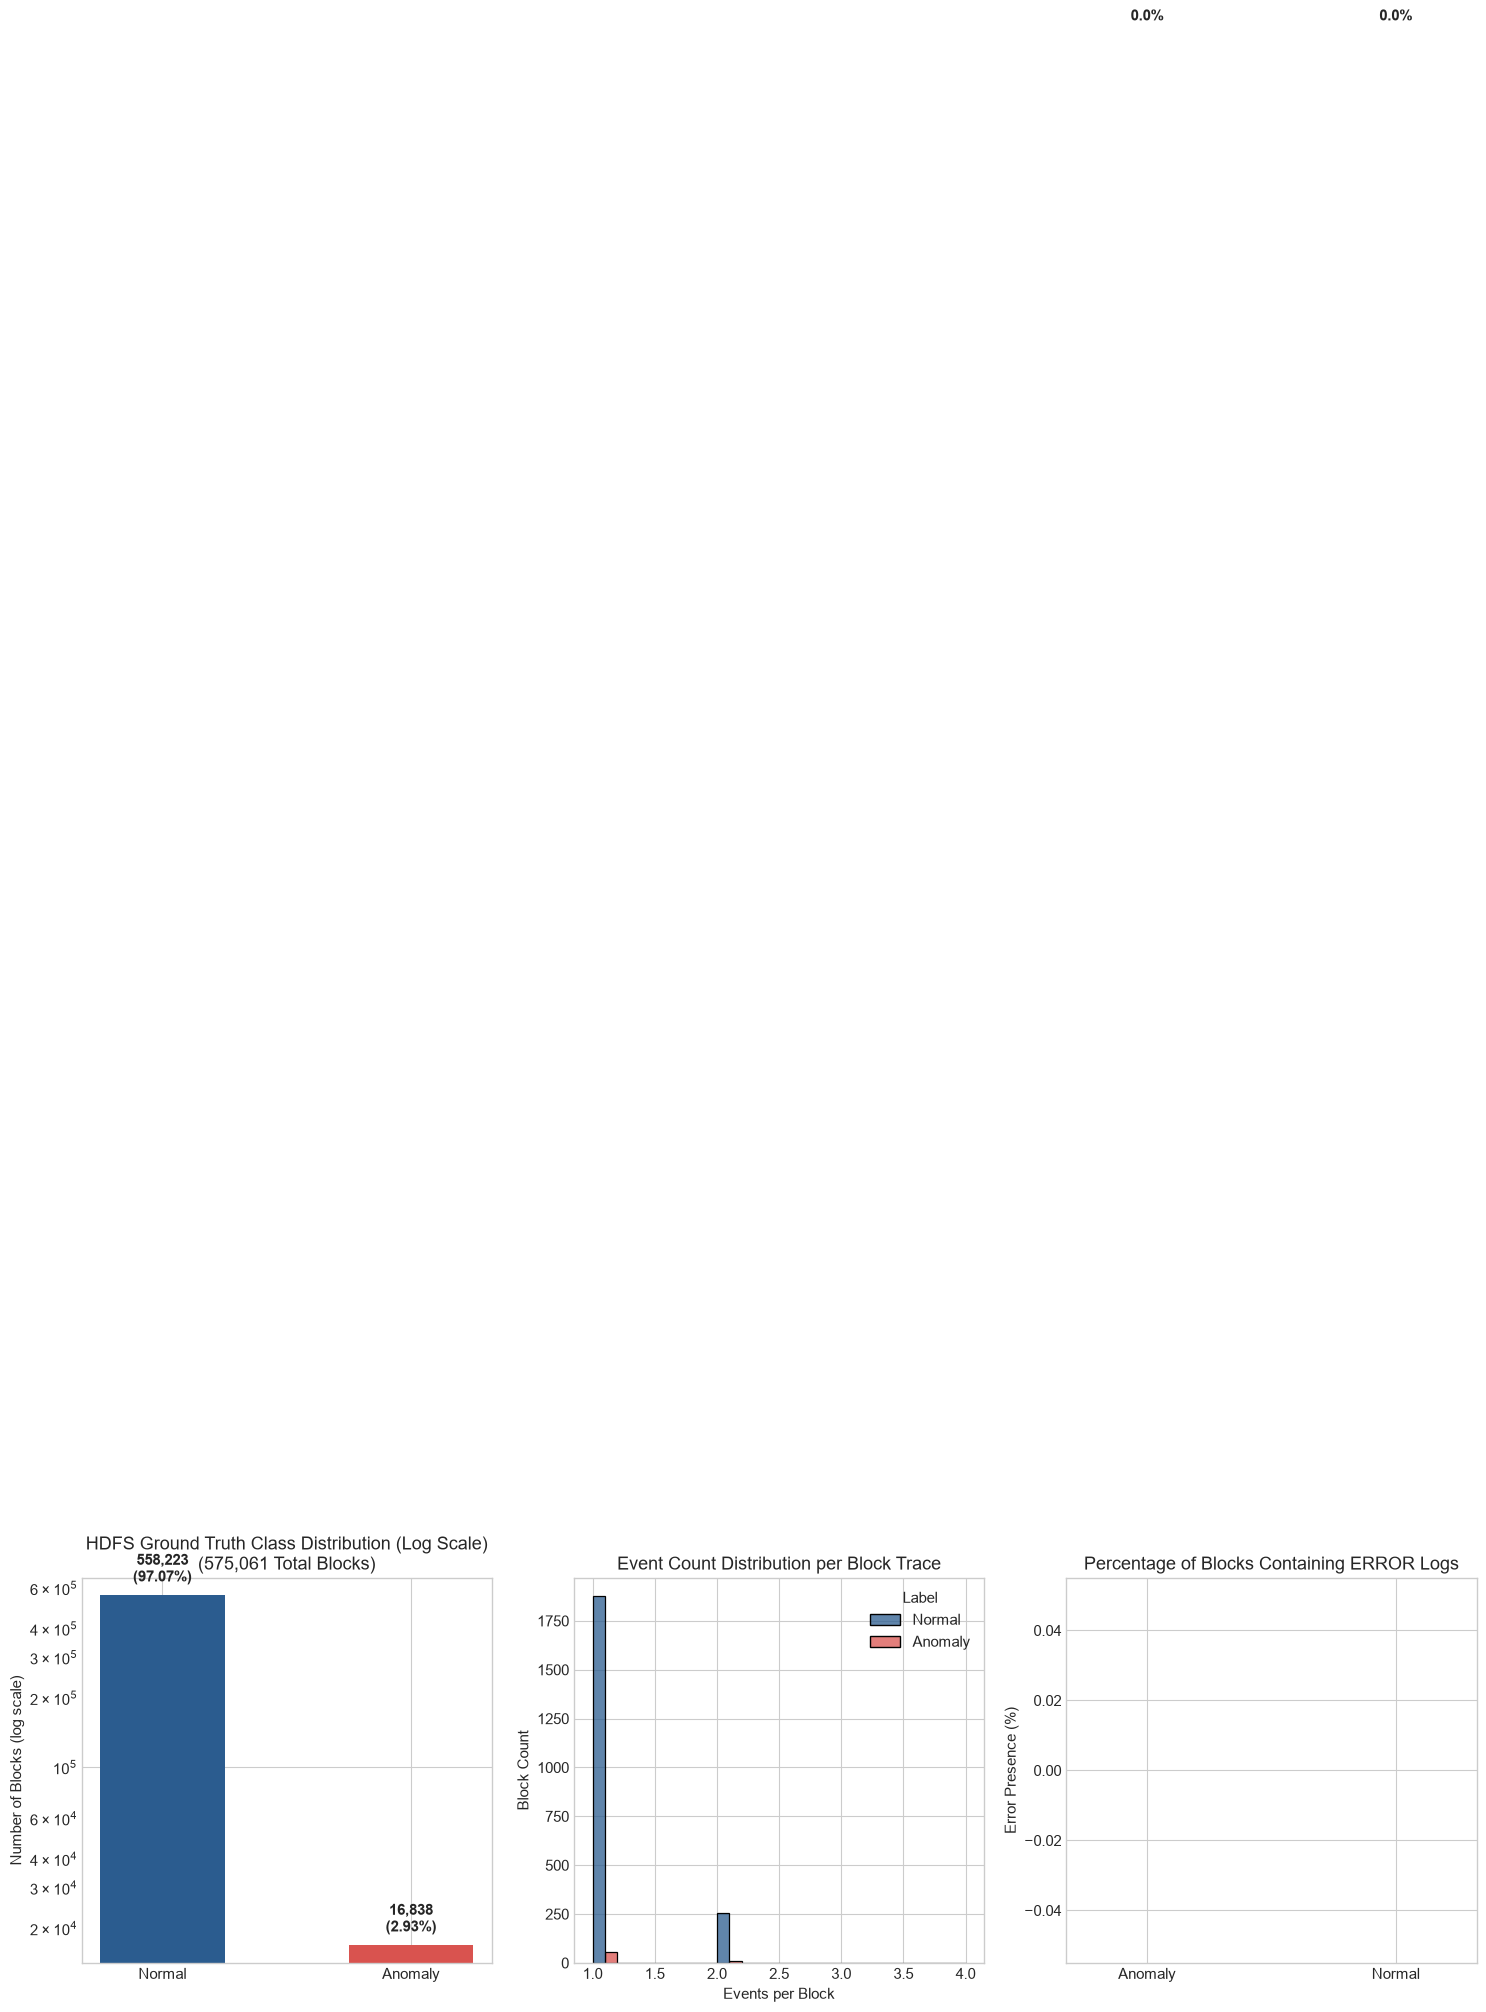

Visualization saved to data/processed/hdfs_data_exploration_summary.png


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Ground-Truth Class Distribution (Full Dataset)
colors = ['#2b5c8f', '#d9534f']
axes[0].bar(['Normal', 'Anomaly'], [label_counts['Normal'], label_counts['Anomaly']], color=colors, width=0.5)
axes[0].set_yscale('log')
axes[0].set_title('HDFS Ground Truth Class Distribution (Log Scale)\n(575,061 Total Blocks)')
axes[0].set_ylabel('Number of Blocks (log scale)')
for i, (cnt, pct) in enumerate(zip(label_counts, label_pcts)):
    axes[0].text(i, cnt * 1.15, f"{cnt:,}\n({pct:.2f}%)", ha='center', fontweight='bold')

# Plot 2: Event Count per Block Distribution
sns.histplot(data=df_blocks, x='EventCount', hue='Label', bins=15, ax=axes[1], palette={'Normal': '#2b5c8f', 'Anomaly': '#d9534f'}, multiple='dodge')
axes[1].set_title('Event Count Distribution per Block Trace')
axes[1].set_xlabel('Events per Block')
axes[1].set_ylabel('Block Count')

# Plot 3: Error Rate by Block Class
error_pct = df_blocks.groupby('Label')['HasError'].mean() * 100
axes[2].bar(error_pct.index, error_pct.values, color=['#2b5c8f', '#d9534f'], width=0.5)
axes[2].set_title('Percentage of Blocks Containing ERROR Logs')
axes[2].set_ylabel('Error Presence (%)')
for i, v in enumerate(error_pct.values):
    axes[2].text(i, v + 0.5, f"{v:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
out_dir = Path('../data/processed')
out_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(out_dir / 'hdfs_data_exploration_summary.png', dpi=150)
plt.show()
print("Visualization saved to data/processed/hdfs_data_exploration_summary.png")


## 7. Key Findings & Architecture Guidance
1. **Block-Level Granularity is Mandatory:** HDFS logs cannot be effectively classified on isolated single lines. A block lifecycle spans multiple events across components (DataNode, FSNamesystem, PacketResponder).
2. **Severe Class Imbalance:** Normal blocks comprise 97.07% while anomalous blocks comprise 2.93% (ratio ~33:1). Unsupervised algorithms (Isolation Forest, LOF, Autoencoders) and evaluation with Precision/Recall/F1/AUC-ROC are critical rather than raw accuracy.
3. **Trace Length Signatures:** Anomalous blocks exhibit distinctive event length profiles and error cascades compared to the typical lifecycle of normal blocks.
4. **Clean Decoupling:** Reusable preprocessor `ml.preprocessing.hdfs_preprocessor.HDFSPreprocessor` robustly extracts Block IDs and isolates malformed records without data loss.
